In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

array([[ 8,  8,  8, ..., 63, 78, 75],
       [ 8,  8,  7, ..., 67, 71, 71],
       [ 9,  8,  8, ..., 53, 64, 66],
       ...,
       [ 8,  9,  8, ..., 17, 24, 59],
       [ 8,  8,  8, ..., 17, 22, 55],
       [ 8,  8,  8, ..., 16, 18, 38]], shape=(512, 512), dtype=uint8)
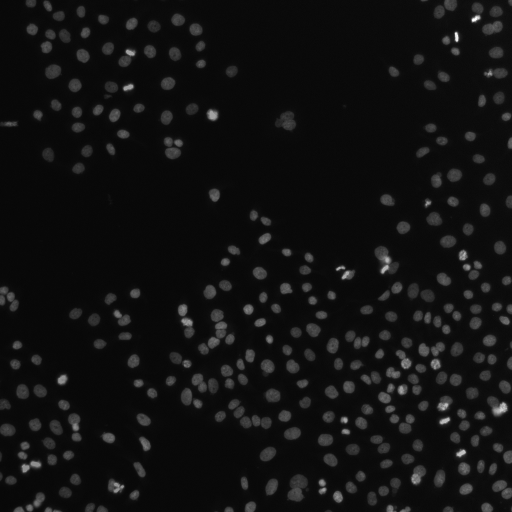

In [ ]:
cells = data.human_mitosis()
cells

In [ ]:
def mostrar(imagens, titulos, cmap="gray", tamanho=4):

  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))

  for i in range(n):
    plt.subplot(1,n,i+1)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis("off")
  plt.show()

In [ ]:
def detectar_contornos(imagem, kernel=(5, 5), bloco=101, c=-10, area_minima=100):
    """
    Segmenta objetos claros em uma imagem em tons de cinza e devolve seus contornos.

    Aplica suavização gaussiana, threshold adaptativo e extração dos contornos
    externos, descartando regiões pequenas (ruído).

    Parameters
    ----------
    imagem : numpy.ndarray
        Imagem em tons de cinza (uint8) com shape (H, W).
    kernel : tuple of int, default=(5, 5)
        Tamanho do kernel do filtro gaussiano (valores ímpares).
    bloco : int, default=101
        Tamanho (ímpar) da vizinhança usada no threshold adaptativo.
    c : int, default=-10
        Constante subtraída da média ponderada no threshold adaptativo.
    area_minima : float, default=100
        Contornos com área menor que este valor são descartados.

    Returns
    -------
    mascara : numpy.ndarray
        Máscara binária (0 ou 255) resultante do threshold adaptativo.
    contornos : list of numpy.ndarray
        Contornos externos com área >= ``area_minima``.
    """
    suave = cv2.GaussianBlur(imagem, kernel, 0)

    mascara = cv2.adaptiveThreshold(
        suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, bloco, c
    )

    contornos = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    contornos = [ct for ct in contornos if cv2.contourArea(ct) >= area_minima]

    return mascara, contornos

In [ ]:
mascara, contornos = detectar_contornos(cells)

In [ ]:
def segmentar_instancias(imagem, **params):
    """
    Gera os mapas de segmentação semântica e por instância de uma imagem.

    Parameters
    ----------
    imagem : numpy.ndarray
        Imagem em tons de cinza (uint8) com shape (H, W).
    **params
        Argumentos repassados a ``detectar_contornos``
        (``kernel``, ``bloco``, ``c``, ``area_minima``).

    Returns
    -------
    semantica : numpy.ndarray
        Máscara booleana: True onde há objeto, False no fundo.
    instancia : numpy.ndarray
        Mapa de rótulos (int32): 0 = fundo, 1..N = um valor por objeto.
    """
    _, contornos = detectar_contornos(imagem, **params)

    instancia = np.zeros(imagem.shape, dtype=np.int32)
    for rotulo, ct in enumerate(contornos, start=1):
        cv2.drawContours(instancia, [ct], -1, rotulo, thickness=-1)

    semantica = instancia > 0
    return semantica, instancia


def plotar_comparacao(imagem, semantica, instancia, nome="objeto"):
    """
    Mostra entrada, segmentação semântica e segmentação por instância.

    Parameters
    ----------
    imagem : numpy.ndarray
        Imagem de entrada em tons de cinza.
    semantica : numpy.ndarray
        Máscara booleana devolvida por ``segmentar_instancias``.
    instancia : numpy.ndarray
        Mapa de rótulos devolvido por ``segmentar_instancias``.
    nome : str, default="objeto"
        Nome da classe, usado nos títulos dos painéis.
    """
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
    eixos[0].imshow(imagem, cmap="gray")
    eixos[0].set_title("Entrada")
    eixos[1].imshow(semantica, cmap="gray")
    eixos[1].set_title(f"Semântica (1 classe: {nome})")
    eixos[2].imshow(instancia, cmap="nipy_spectral")
    eixos[2].set_title(f"Instância (1 cor por {nome})")
    for ax in eixos:
        ax.axis("off")
    plt.show()

104


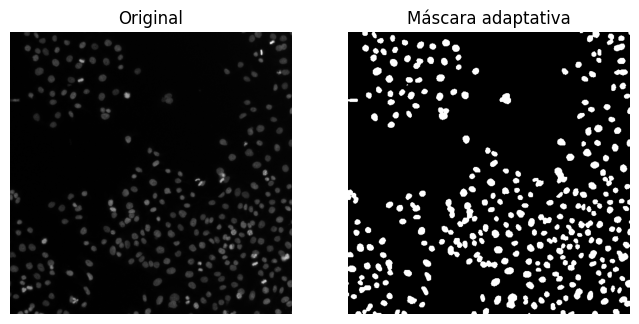

In [ ]:
print(len(contornos))
mostrar([cells, mascara], ["Original", "Máscara adaptativa"])

In [ ]:
semantica, instancia = segmentar_instancias(cells)

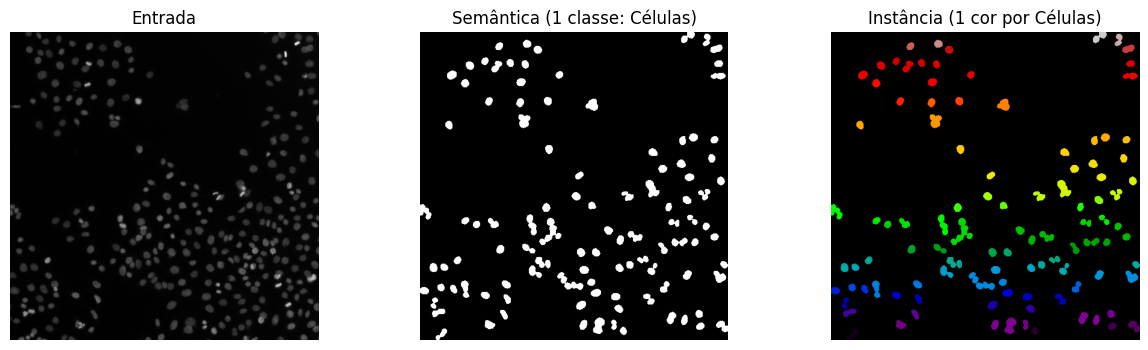

In [ ]:
plotar_comparacao(cells, semantica, instancia, nome="Células")

array([[[15,  7,  4],
        [15,  9,  9],
        [ 9,  4,  8],
        ...,
        [18, 11,  5],
        [16, 19, 10],
        [15, 10,  6]],

       [[ 2,  7,  0],
        [ 5, 11,  7],
        [13, 19, 17],
        ...,
        [11, 10,  5],
        [13, 18, 11],
        [ 9, 11,  6]],

       [[10, 15,  9],
        [13, 18, 14],
        [18, 22, 23],
        ...,
        [ 1,  2,  0],
        [14, 15, 10],
        [ 8, 14, 10]],

       ...,

       [[19, 20, 14],
        [15, 15, 13],
        [13, 13, 13],
        ...,
        [ 2,  6,  5],
        [12, 14, 13],
        [ 7,  9,  8]],

       [[13, 10,  5],
        [ 9, 11,  8],
        [12, 18, 16],
        ...,
        [ 5,  9,  8],
        [ 6, 12, 10],
        [ 7, 13,  9]],

       [[21, 16, 12],
        [10, 12,  9],
        [ 9, 20, 16],
        ...,
        [11, 15, 14],
        [ 9, 18, 15],
        [ 7, 18, 12]]], shape=(872, 1000, 3), dtype=uint8)
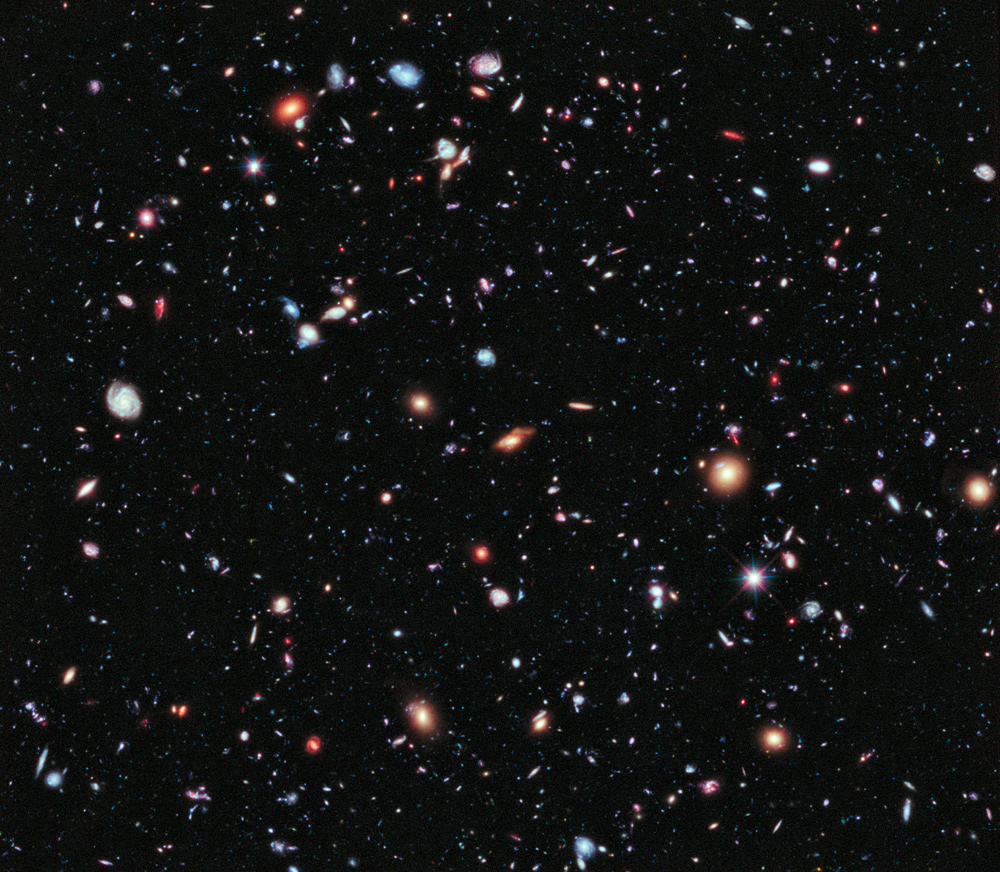

In [23]:
image = data.hubble_deep_field()
image

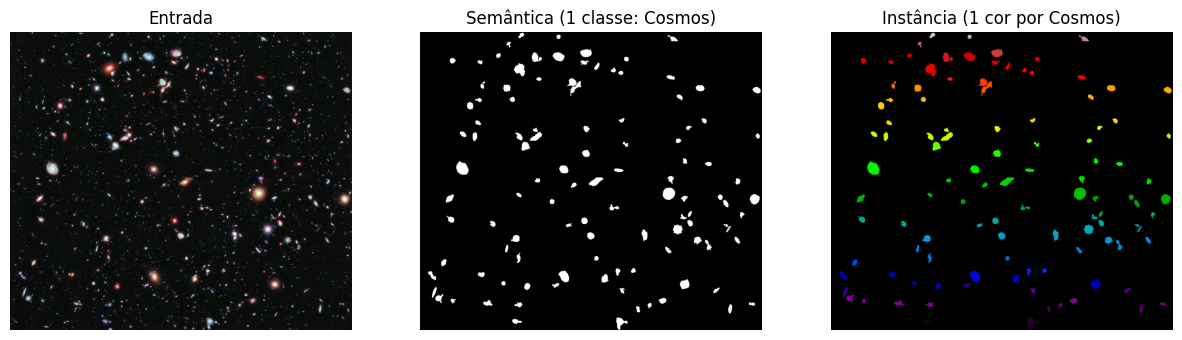

In [26]:
gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
semantica, instancia = segmentar_instancias(gray_image)
plotar_comparacao(image, semantica, instancia, nome="Cosmos")

Uma imagem, como a do cosmos, onde os objetos tem tamanhos bem distintos até são segmentados de forma semântica corretamente na maior parte dos casos (apesar de tratar uma ou outra estrela como uma galáxia). Contudo, por alguma razão as instâncias estão sendo instanciadas em grupos conforme a disposição delas em ambas as imagens (vermelhas depois das rosadas, verdes no meio entre outros).